In [1]:
from pathlib import Path
import json
from collections import Counter

RAW_DIR = Path(r"E:\ReNexa\data\raw")

print("Raw dataset directory:", RAW_DIR)
print("Exists:", RAW_DIR.exists())

if not RAW_DIR.exists():
    raise FileNotFoundError(f"Raw directory not found: {RAW_DIR}")

print("\nDatasets found:")
for item in sorted(RAW_DIR.iterdir()):
    if item.is_dir():
        print(" -", item.name)

Raw dataset directory: E:\ReNexa\data\raw
Exists: True

Datasets found:
 - asian_waste
 - mju_waste
 - mmorwad
 - taco
 - trashnet
 - zerowaste-f-final


In [2]:
def show_tree(folder, max_depth=3, max_items=20):
    folder = Path(folder)

    print(f"\n{'=' * 70}")
    print(f"STRUCTURE: {folder}")
    print(f"{'=' * 70}")

    def walk(path, depth):
        if depth > max_depth:
            return

        try:
            items = sorted(path.iterdir(), key=lambda x: (not x.is_dir(), x.name.lower()))
        except PermissionError:
            print("  " * depth + "[Permission denied]")
            return

        shown = 0

        for item in items:
            if shown >= max_items:
                remaining = len(items) - shown
                print("  " * depth + f"... {remaining} more items")
                break

            if item.is_dir():
                print("  " * depth + f"[DIR]  {item.name}/")
                walk(item, depth + 1)
            else:
                print("  " * depth + f"[FILE] {item.name}")

            shown += 1

    walk(folder, 0)


for dataset in sorted(RAW_DIR.iterdir()):
    if dataset.is_dir():
        show_tree(dataset, max_depth=2, max_items=15)


STRUCTURE: E:\ReNexa\data\raw\asian_waste
[DIR]  test/
  [DIR]  images/
    [FILE] test_000001.jpg
    [FILE] test_000002.jpg
    [FILE] test_000003.jpg
    [FILE] test_000004.jpg
    [FILE] test_000005.jpg
    [FILE] test_000006.jpg
    [FILE] test_000007.jpg
    [FILE] test_000008.jpg
    [FILE] test_000009.jpg
    [FILE] test_000010.jpg
    [FILE] test_000011.jpg
    [FILE] test_000012.jpg
    [FILE] test_000013.jpg
    [FILE] test_000014.jpg
    [FILE] test_000015.jpg
    ... 1321 more items
  [DIR]  labels/
    [FILE] test_000001.txt
    [FILE] test_000002.txt
    [FILE] test_000003.txt
    [FILE] test_000004.txt
    [FILE] test_000005.txt
    [FILE] test_000006.txt
    [FILE] test_000007.txt
    [FILE] test_000008.txt
    [FILE] test_000009.txt
    [FILE] test_000010.txt
    [FILE] test_000011.txt
    [FILE] test_000012.txt
    [FILE] test_000013.txt
    [FILE] test_000014.txt
    [FILE] test_000015.txt
    ... 1321 more items
[DIR]  train/
  [DIR]  images/
    [FILE] train_0000

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

ANNOTATION_EXTENSIONS = {
    ".txt", ".json", ".xml", ".csv", ".yaml", ".yml", ".mask"
}


def inspect_files(dataset_path):
    image_count = 0
    annotation_count = 0

    image_extensions = Counter()
    annotation_extensions = Counter()

    for path in dataset_path.rglob("*"):
        if not path.is_file():
            continue

        suffix = path.suffix.lower()

        if suffix in IMAGE_EXTENSIONS:
            image_count += 1
            image_extensions[suffix] += 1

        elif suffix in ANNOTATION_EXTENSIONS:
            annotation_count += 1
            annotation_extensions[suffix] += 1

    return {
        "images": image_count,
        "annotations": annotation_count,
        "image_extensions": dict(image_extensions),
        "annotation_extensions": dict(annotation_extensions),
    }


print("\nDATASET FILE SUMMARY")
print("=" * 80)

dataset_summaries = {}

for dataset in sorted(RAW_DIR.iterdir()):
    if not dataset.is_dir():
        continue

    summary = inspect_files(dataset)
    dataset_summaries[dataset.name] = summary

    print(f"\n{dataset.name}")
    print("  Images:", summary["images"])
    print("  Annotations:", summary["annotations"])
    print("  Image extensions:", summary["image_extensions"])
    print("  Annotation extensions:", summary["annotation_extensions"])


DATASET FILE SUMMARY

asian_waste
  Images: 12627
  Annotations: 12630
  Image extensions: {'.jpg': 12627}
  Annotation extensions: {'.yaml': 1, '.txt': 12629}

mju_waste
  Images: 7425
  Annotations: 5
  Image extensions: {'.png': 7425}
  Annotation extensions: {'.txt': 5}

mmorwad
  Images: 3300
  Annotations: 5
  Image extensions: {'.png': 3300}
  Annotation extensions: {'.json': 1, '.csv': 4}

taco
  Images: 1500
  Annotations: 21
  Image extensions: {'.jpg': 1500}
  Annotation extensions: {'.txt': 1, '.json': 16, '.csv': 4}

trashnet
  Images: 2527
  Annotations: 0
  Image extensions: {'.jpg': 2527}
  Annotation extensions: {}

zerowaste-f-final
  Images: 9006
  Annotations: 3
  Image extensions: {'.png': 9006}
  Annotation extensions: {'.json': 3}


In [4]:
def find_files(dataset_path, extensions):
    files = []

    for path in dataset_path.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            files.append(path)

    return files


def detect_annotation_formats(dataset_path):
    formats = []

    # YOLO-style TXT files
    txt_files = find_files(dataset_path, {".txt"})

    yolo_like = 0

    for txt in txt_files[:20]:
        try:
            lines = txt.read_text(encoding="utf-8", errors="ignore").splitlines()

            valid_lines = 0

            for line in lines[:20]:
                parts = line.strip().split()

                if len(parts) == 5:
                    values = [float(x) for x in parts]

                    # YOLO format:
                    # class_id x_center y_center width height
                    if (
                        values[0].is_integer()
                        and 0 <= values[1] <= 1
                        and 0 <= values[2] <= 1
                        and 0 <= values[3] <= 1
                        and 0 <= values[4] <= 1
                    ):
                        valid_lines += 1

            if valid_lines > 0:
                yolo_like += 1

        except Exception:
            pass

    if yolo_like > 0:
        formats.append(f"YOLO-like TXT ({yolo_like} sample files)")

    # JSON files
    json_files = find_files(dataset_path, {".json"})

    coco_like = 0
    other_json = 0

    for json_file in json_files[:20]:
        try:
            with open(json_file, "r", encoding="utf-8") as f:
                data = json.load(f)

            if isinstance(data, dict):
                keys = set(data.keys())

                if {"images", "annotations", "categories"}.issubset(keys):
                    coco_like += 1
                else:
                    other_json += 1

        except Exception:
            pass

    if coco_like > 0:
        formats.append(f"COCO JSON ({coco_like} sample files)")

    if other_json > 0:
        formats.append(f"Other JSON ({other_json} sample files)")

    # XML
    xml_files = find_files(dataset_path, {".xml"})

    if xml_files:
        formats.append(f"XML ({len(xml_files)} files)")

    # Masks
    mask_keywords = {
        "mask",
        "masks",
        "segmentation",
        "segmentationclass"
    }

    mask_dirs = []

    for path in dataset_path.rglob("*"):
        if path.is_dir() and path.name.lower() in mask_keywords:
            mask_dirs.append(path)

    if mask_dirs:
        formats.append(
            "Segmentation/mask directories: "
            + ", ".join(p.name for p in mask_dirs)
        )

    if not formats:
        formats.append("Unknown / needs manual inspection")

    return formats


print("\nANNOTATION FORMAT DETECTION")
print("=" * 80)

for dataset in sorted(RAW_DIR.iterdir()):
    if not dataset.is_dir():
        continue

    formats = detect_annotation_formats(dataset)

    print(f"\n{dataset.name}")

    for fmt in formats:
        print("  -", fmt)


ANNOTATION FORMAT DETECTION

asian_waste
  - YOLO-like TXT (18 sample files)

mju_waste
  - Segmentation/mask directories: SegmentationClass, Segmentation

mmorwad
  - COCO JSON (1 sample files)

taco
  - COCO JSON (16 sample files)

trashnet
  - Unknown / needs manual inspection

zerowaste-f-final
  - COCO JSON (3 sample files)


In [5]:
def inspect_json_file(json_file):
    print("\n" + "=" * 80)
    print("JSON FILE:", json_file)
    print("=" * 80)

    try:
        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)
    except Exception as e:
        print("Could not read JSON:", e)
        return

    print("Top-level type:", type(data).__name__)

    if isinstance(data, dict):
        print("Top-level keys:")
        for key in data.keys():
            value = data[key]

            if isinstance(value, list):
                print(f"  {key}: list ({len(value)} items)")
            elif isinstance(value, dict):
                print(f"  {key}: dictionary ({len(value)} keys)")
            else:
                print(f"  {key}: {type(value).__name__}")

        # COCO-style information
        if "categories" in data and isinstance(data["categories"], list):
            print("\nCategories:")

            for category in data["categories"][:30]:
                print(" ", category)

            if len(data["categories"]) > 30:
                print("  ... more categories")

        if "images" in data and isinstance(data["images"], list):
            print("\nFirst image record:")
            if data["images"]:
                print(data["images"][0])

        if "annotations" in data and isinstance(data["annotations"], list):
            print("\nFirst annotation record:")
            if data["annotations"]:
                print(data["annotations"][0])

    elif isinstance(data, list):
        print("First item:")
        if data:
            print(data[0])


for dataset_name in ["taco", "mmorwad", "zerowaste-f-final"]:
    dataset_path = RAW_DIR / dataset_name

    if not dataset_path.exists():
        print(f"\nDataset not found: {dataset_name}")
        continue

    json_files = list(dataset_path.rglob("*.json"))

    print(f"\n\n### {dataset_name.upper()} ###")
    print("JSON files found:", len(json_files))

    for json_file in json_files[:5]:
        inspect_json_file(json_file)



### TACO ###
JSON files found: 16

JSON FILE: E:\ReNexa\data\raw\taco\TACO\data\annotations.json
Top-level type: dict
Top-level keys:
  info: dictionary (6 keys)
  images: list (1500 items)
  annotations: list (4784 items)
  scene_annotations: list (4296 items)
  licenses: list (0 items)
  categories: list (60 items)
  scene_categories: list (7 items)

Categories:
  {'supercategory': 'Aluminium foil', 'id': 0, 'name': 'Aluminium foil'}
  {'supercategory': 'Battery', 'id': 1, 'name': 'Battery'}
  {'supercategory': 'Blister pack', 'id': 2, 'name': 'Aluminium blister pack'}
  {'supercategory': 'Blister pack', 'id': 3, 'name': 'Carded blister pack'}
  {'supercategory': 'Bottle', 'id': 4, 'name': 'Other plastic bottle'}
  {'supercategory': 'Bottle', 'id': 5, 'name': 'Clear plastic bottle'}
  {'supercategory': 'Bottle', 'id': 6, 'name': 'Glass bottle'}
  {'supercategory': 'Bottle cap', 'id': 7, 'name': 'Plastic bottle cap'}
  {'supercategory': 'Bottle cap', 'id': 8, 'name': 'Metal bottle c

In [6]:
def inspect_yolo_samples(dataset_path, max_files=5):
    txt_files = list(dataset_path.rglob("*.txt"))

    print("\n" + "=" * 80)
    print("YOLO SAMPLE INSPECTION:", dataset_path.name)
    print("=" * 80)

    print("TXT files found:", len(txt_files))

    shown = 0

    for txt_file in txt_files:

        # Skip obvious README/config files
        if txt_file.name.lower() in {
            "readme.txt",
            "classes.txt",
            "class_names.txt"
        }:
            continue

        try:
            lines = txt_file.read_text(
                encoding="utf-8",
                errors="ignore"
            ).splitlines()

            print("\nFile:", txt_file.relative_to(dataset_path))

            for line in lines[:5]:
                print(" ", line)

            shown += 1

            if shown >= max_files:
                break

        except Exception as e:
            print("  Error:", e)


for dataset_name in ["asian_waste"]:
    dataset_path = RAW_DIR / dataset_name

    if dataset_path.exists():
        inspect_yolo_samples(dataset_path)


YOLO SAMPLE INSPECTION: asian_waste
TXT files found: 12629

File: README.dataset.txt
  # Asian Waste Detection > 2026-04-02 9:17pm
  https://universe.roboflow.com/fyp-loofa/asian-waste-detection-dihfa-m9t9o-hqccl-4ptpz
  
  Provided by a Roboflow user
  License: CC BY 4.0

File: README.roboflow.txt
  
  Asian Waste Detection - v8 2026-04-02 9:17pm
  
  This dataset was exported via roboflow.com on April 2, 2026 at 4:24 PM GMT

File: test\labels\test_000001.txt
  5 0.478125 0.4828125 0.84296875 0.5984375

File: test\labels\test_000002.txt
  5 0.521875 0.51328125 0.55703125 0.79296875

File: test\labels\test_000003.txt
  5 0.5140625 0.4984375 0.8515625 0.7546875


In [7]:
CLASS_FILE_NAMES = {
    "classes.txt",
    "class_names.txt",
    "classes.names",
    "names.txt",
    "data.yaml",
    "dataset.yaml",
    "data.yml",
    "dataset.yml"
}

print("\nPOSSIBLE CLASS / CONFIG FILES")
print("=" * 80)

for dataset in sorted(RAW_DIR.iterdir()):

    if not dataset.is_dir():
        continue

    found = []

    for path in dataset.rglob("*"):
        if path.is_file() and path.name.lower() in CLASS_FILE_NAMES:
            found.append(path)

    print(f"\n{dataset.name}")

    if found:
        for file in found[:20]:
            print("  -", file.relative_to(dataset))
    else:
        print("  None found")


POSSIBLE CLASS / CONFIG FILES

asian_waste
  - data.yaml

mju_waste
  None found

mmorwad
  None found

taco
  None found

trashnet
  None found

zerowaste-f-final
  None found


In [8]:
SPLIT_NAMES = {
    "train",
    "training",
    "val",
    "valid",
    "validation",
    "test",
    "testing"
}


def find_split_directories(dataset_path):
    splits = {}

    for path in dataset_path.rglob("*"):

        if not path.is_dir():
            continue

        name = path.name.lower()

        if name in SPLIT_NAMES:
            image_count = sum(
                1
                for file in path.rglob("*")
                if file.is_file()
                and file.suffix.lower() in IMAGE_EXTENSIONS
            )

            splits[path.name] = {
                "path": str(path),
                "images": image_count
            }

    return splits


print("\nDATASET SPLIT STRUCTURE")
print("=" * 80)

for dataset in sorted(RAW_DIR.iterdir()):

    if not dataset.is_dir():
        continue

    splits = find_split_directories(dataset)

    print(f"\n{dataset.name}")

    if splits:
        for name, info in splits.items():
            print(
                f"  {name}: "
                f"{info['images']} images"
            )
            print(
                f"      {info['path']}"
            )
    else:
        print("  No obvious train/val/test folders found")


DATASET SPLIT STRUCTURE

asian_waste
  test: 1336 images
      E:\ReNexa\data\raw\asian_waste\test
  train: 9964 images
      E:\ReNexa\data\raw\asian_waste\train
  valid: 1327 images
      E:\ReNexa\data\raw\asian_waste\valid

mju_waste
  No obvious train/val/test folders found

mmorwad
  No obvious train/val/test folders found

taco
  No obvious train/val/test folders found

trashnet
  No obvious train/val/test folders found

zerowaste-f-final
  test: 1858 images
      E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\test
  train: 6004 images
      E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\train
  val: 1144 images
      E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\val


In [9]:
print("\n")
print("=" * 90)
print("RENEXA DATASET STRUCTURE INSPECTION REPORT")
print("=" * 90)

for dataset in sorted(RAW_DIR.iterdir()):

    if not dataset.is_dir():
        continue

    summary = inspect_files(dataset)
    formats = detect_annotation_formats(dataset)
    splits = find_split_directories(dataset)

    print(f"\nDATASET: {dataset.name}")
    print("-" * 60)

    print("Images:", summary["images"])
    print("Annotations:", summary["annotations"])

    print("Image formats:")
    for ext, count in summary["image_extensions"].items():
        print(f"  {ext}: {count}")

    print("Annotation formats:")
    for ext, count in summary["annotation_extensions"].items():
        print(f"  {ext}: {count}")

    print("Detected structures:")
    for fmt in formats:
        print(f"  - {fmt}")

    print("Splits:")
    if splits:
        for split, info in splits.items():
            print(f"  - {split}: {info['images']} images")
    else:
        print("  - No standard split detected")

print("\n")
print("=" * 90)
print("INSPECTION COMPLETE")
print("=" * 90)
print("No files were modified.")




RENEXA DATASET STRUCTURE INSPECTION REPORT

DATASET: asian_waste
------------------------------------------------------------
Images: 12627
Annotations: 12630
Image formats:
  .jpg: 12627
Annotation formats:
  .yaml: 1
  .txt: 12629
Detected structures:
  - YOLO-like TXT (18 sample files)
Splits:
  - test: 1336 images
  - train: 9964 images
  - valid: 1327 images

DATASET: mju_waste
------------------------------------------------------------
Images: 7425
Annotations: 5
Image formats:
  .png: 7425
Annotation formats:
  .txt: 5
Detected structures:
  - Segmentation/mask directories: SegmentationClass, Segmentation
Splits:
  - No standard split detected

DATASET: mmorwad
------------------------------------------------------------
Images: 3300
Annotations: 5
Image formats:
  .png: 3300
Annotation formats:
  .json: 1
  .csv: 4
Detected structures:
  - COCO JSON (1 sample files)
Splits:
  - No standard split detected

DATASET: taco
--------------------------------------------------------

In [10]:
from pathlib import Path
import csv

REPORT_DIR = RAW_DIR.parent / "processed" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_file = REPORT_DIR / "dataset_structure_inspection.csv"

rows = []

for dataset in sorted(RAW_DIR.iterdir()):

    if not dataset.is_dir():
        continue

    summary = inspect_files(dataset)
    formats = detect_annotation_formats(dataset)
    splits = find_split_directories(dataset)

    split_text = "; ".join(
        f"{name}={info['images']}"
        for name, info in splits.items()
    )

    rows.append({
        "dataset": dataset.name,
        "images": summary["images"],
        "annotations": summary["annotations"],
        "image_formats": str(summary["image_extensions"]),
        "annotation_formats": str(summary["annotation_extensions"]),
        "detected_formats": " | ".join(formats),
        "splits": split_text if split_text else "none"
    })


with open(report_file, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "dataset",
            "images",
            "annotations",
            "image_formats",
            "annotation_formats",
            "detected_formats",
            "splits"
        ]
    )

    writer.writeheader()
    writer.writerows(rows)


print("Inspection report saved:")
print(report_file)

print("\nCOMPACT SUMMARY")
print("=" * 100)

for row in rows:
    print(
        f"{row['dataset']:<20} "
        f"images={row['images']:<6} "
        f"annotations={row['annotations']:<6} "
        f"splits={row['splits']}"
    )

Inspection report saved:
E:\ReNexa\data\processed\reports\dataset_structure_inspection.csv

COMPACT SUMMARY
asian_waste          images=12627  annotations=12630  splits=test=1336; train=9964; valid=1327
mju_waste            images=7425   annotations=5      splits=none
mmorwad              images=3300   annotations=5      splits=none
taco                 images=1500   annotations=21     splits=none
trashnet             images=2527   annotations=0      splits=none
zerowaste-f-final    images=9006   annotations=3      splits=test=1858; train=6004; val=1144


In [3]:
import pandas as pd

inspection = pd.read_csv(
    r"E:\ReNexa\data\processed\reports\dataset_structure_inspection.csv"
)

display(inspection)

,dataset,images,annotations,image_formats,annotation_formats,detected_formats,splits
0,asian_waste,12627,12630,{'.jpg': 12627},"{'.yaml': 1, '.txt': 12629}",YOLO-like TXT (18 sample files),test=1336; train=9964; valid=1327
1,mju_waste,7425,5,{'.png': 7425},{'.txt': 5},Segmentation/mask directories: SegmentationCla...,none
2,mmorwad,3300,5,{'.png': 3300},"{'.json': 1, '.csv': 4}",COCO JSON (1 sample files),none
3,taco,1500,21,{'.jpg': 1500},"{'.txt': 1, '.json': 16, '.csv': 4}",COCO JSON (16 sample files),none
4,trashnet,2527,0,{'.jpg': 2527},{},Unknown / needs manual inspection,none
5,zerowaste-f-final,9006,3,{'.png': 9006},{'.json': 3},COCO JSON (3 sample files),test=1858; train=6004; val=1144


In [4]:
print("=" * 80)
print("DATASET STRUCTURE SUMMARY")
print("=" * 80)

for _, row in inspection.iterrows():
    print(f"\nDataset: {row['dataset']}")
    print(f"Images: {row['images']}")
    print(f"Annotations: {row['annotations']}")
    print(f"Image formats: {row['image_formats']}")
    print(f"Annotation formats: {row['annotation_formats']}")
    print(f"Detected formats: {row['detected_formats']}")
    print(f"Splits: {row['splits']}")

DATASET STRUCTURE SUMMARY

Dataset: asian_waste
Images: 12627
Annotations: 12630
Image formats: {'.jpg': 12627}
Annotation formats: {'.yaml': 1, '.txt': 12629}
Detected formats: YOLO-like TXT (18 sample files)
Splits: test=1336; train=9964; valid=1327

Dataset: mju_waste
Images: 7425
Annotations: 5
Image formats: {'.png': 7425}
Annotation formats: {'.txt': 5}
Detected formats: Segmentation/mask directories: SegmentationClass, Segmentation
Splits: none

Dataset: mmorwad
Images: 3300
Annotations: 5
Image formats: {'.png': 3300}
Annotation formats: {'.json': 1, '.csv': 4}
Detected formats: COCO JSON (1 sample files)
Splits: none

Dataset: taco
Images: 1500
Annotations: 21
Image formats: {'.jpg': 1500}
Annotation formats: {'.txt': 1, '.json': 16, '.csv': 4}
Detected formats: COCO JSON (16 sample files)
Splits: none

Dataset: trashnet
Images: 2527
Annotations: 0
Image formats: {'.jpg': 2527}
Annotation formats: {}
Detected formats: Unknown / needs manual inspection
Splits: none

Dataset: ze

In [5]:
from pathlib import Path
import pandas as pd

# --------------------------------------------------
# ReNexa clean detection dataset setup
# --------------------------------------------------

RAW_DIR = Path(r"E:\ReNexa\data\raw")

FINAL_DIR = Path(
    r"E:\ReNexa\data\processed\renexa_detection_final"
)

MAPPING_FILE = Path(
    r"E:\ReNexa\data\processed\reports\renexa_class_mapping_final.csv"
)

# Check required paths
print("Checking required paths...\n")

print("RAW DATA:", RAW_DIR.exists())
print("CLASS MAPPING:", MAPPING_FILE.exists())

if not RAW_DIR.exists():
    raise FileNotFoundError(
        f"Raw dataset directory not found: {RAW_DIR}"
    )

if not MAPPING_FILE.exists():
    raise FileNotFoundError(
        f"Final class mapping not found: {MAPPING_FILE}"
    )

# Final ReNexa classes
FINAL_CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "organic",
    "other",
    "paper",
    "plastic"
]

CLASS_TO_ID = {
    name: index
    for index, name in enumerate(FINAL_CLASSES)
}

print("\nFinal ReNexa classes:")
for class_id, class_name in enumerate(FINAL_CLASSES):
    print(f"{class_id}: {class_name}")

print("\nSetup successful.")

Checking required paths...

RAW DATA: True
CLASS MAPPING: True

Final ReNexa classes:
0: cardboard
1: glass
2: metal
3: organic
4: other
5: paper
6: plastic

Setup successful.


In [6]:
# Create final dataset structure

for split in ["train", "val", "test"]:

    image_dir = FINAL_DIR / split / "images"
    label_dir = FINAL_DIR / split / "labels"

    image_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    label_dir.mkdir(
        parents=True,
        exist_ok=True
    )

print("Final dataset structure created:")
print(FINAL_DIR)

for split in ["train", "val", "test"]:
    print(f"  {split}/")
    print("    images/")
    print("    labels/")

Final dataset structure created:
E:\ReNexa\data\processed\renexa_detection_final
  train/
    images/
    labels/
  val/
    images/
    labels/
  test/
    images/
    labels/


In [7]:
from pathlib import Path
import shutil
import hashlib
import pandas as pd


# --------------------------------------------------
# Asian Waste → ReNexa Detection Dataset
# --------------------------------------------------

ASIAN_DIR = RAW_DIR / "asian_waste"

if not ASIAN_DIR.exists():
    raise FileNotFoundError(
        f"Asian Waste dataset not found: {ASIAN_DIR}"
    )

print("Asian Waste directory:")
print(ASIAN_DIR)


# --------------------------------------------------
# Load final class mapping
# --------------------------------------------------

mapping_df = pd.read_csv(MAPPING_FILE)

asian_mapping = mapping_df[
    mapping_df["dataset"].astype(str).str.lower() == "asian_waste"
].copy()

print("\nAsian Waste mappings:")
display(asian_mapping)


# --------------------------------------------------
# Build original-class → ReNexa-class mapping
# --------------------------------------------------

asian_class_mapping = {}

for _, row in asian_mapping.iterrows():

    original_class = str(
        row["original_class"]
    ).strip()

    renexa_class = str(
        row["proposed_renexa_class"]
    ).strip().lower()

    if renexa_class in CLASS_TO_ID:
        asian_class_mapping[original_class] = renexa_class


print("\nAsian Waste class mapping:")

for original_class, renexa_class in asian_class_mapping.items():
    print(
        f"{original_class}  →  "
        f"{renexa_class} "
        f"(ID {CLASS_TO_ID[renexa_class]})"
    )

Asian Waste directory:
E:\ReNexa\data\raw\asian_waste

Asian Waste mappings:


,dataset,original_class,proposed_renexa_class,decision,reason,confidence_of_mapping,notes
137,asian_waste,Plastic,plastic,KEEP,direct match,high,NaN
138,asian_waste,Garbage Bag,plastic,MERGE,garbage bags are plastic,medium,NaN
139,asian_waste,Glass,glass,KEEP,direct match,high,NaN
140,asian_waste,Metal,metal,KEEP,direct match,high,NaN
141,asian_waste,Organic,organic,KEEP,direct match,high,NaN
142,asian_waste,Animal Waste,organic,MERGE,organic waste,medium,NaN
143,asian_waste,waste,other,MERGE,Mapped to the closest ReNexa material category...,high,NaN
144,asian_waste,Paper,paper,KEEP,direct match,high,NaN
145,asian_waste,Construction Waste,other,MERGE,Mixed/non-core construction waste,medium,NaN



Asian Waste class mapping:
Plastic  →  plastic (ID 6)
Garbage Bag  →  plastic (ID 6)
Glass  →  glass (ID 1)
Metal  →  metal (ID 2)
Organic  →  organic (ID 3)
Animal Waste  →  organic (ID 3)
waste  →  other (ID 4)
Paper  →  paper (ID 5)
Construction Waste  →  other (ID 4)


Asian Waste annotation cleaner ready.


In [11]:
import yaml

yaml_files = list(ASIAN_DIR.rglob("*.yaml"))

print("YAML files found:")

for file in yaml_files:
    print(" -", file.relative_to(ASIAN_DIR))


if not yaml_files:
    raise FileNotFoundError(
        "No YAML file found in Asian Waste dataset."
    )


yaml_file = yaml_files[0]

with open(
    yaml_file,
    "r",
    encoding="utf-8"
) as f:
    asian_yaml = yaml.safe_load(f)


print("\nYAML file:")
print(yaml_file)

print("\nYAML keys:")
print(list(asian_yaml.keys()))

print("\nClass information:")

if "names" in asian_yaml:
    print(asian_yaml["names"])

elif "classes" in asian_yaml:
    print(asian_yaml["classes"])

else:
    print("No class list found in YAML.")

YAML files found:
 - data.yaml

YAML file:
E:\ReNexa\data\raw\asian_waste\data.yaml

YAML keys:
['train', 'val', 'test', 'nc', 'names', 'roboflow']

Class information:
['Animal Waste', 'Construction Waste', 'Garbage Bag', 'Glass', 'Metal', 'Organic', 'Paper', 'Plastic', 'waste']


In [12]:
# --------------------------------------------------
# Clean Asian Waste YOLO annotations
# --------------------------------------------------

import hashlib
import shutil


def get_file_hash(file_path):
    """
    Calculate SHA-256 hash of an image.
    Used to detect exact duplicate images.
    """
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


def clean_yolo_annotation(
    label_file,
    original_to_renexa
):
    """
    Read one YOLO annotation file,
    apply ReNexa class mapping,
    and remove invalid boxes.
    """

    valid_lines = []
    invalid_count = 0
    remapped_count = 0

    try:
        lines = label_file.read_text(
            encoding="utf-8",
            errors="ignore"
        ).splitlines()
    except Exception:
        return [], 0, 0

    for line in lines:

        line = line.strip()

        if not line:
            continue

        parts = line.split()

        # YOLO annotation must contain:
        # class x_center y_center width height
        if len(parts) != 5:
            invalid_count += 1
            continue

        try:
            original_class_id = int(float(parts[0]))

            x_center = float(parts[1])
            y_center = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

        except ValueError:
            invalid_count += 1
            continue

        # Check original class ID
        if (
            original_class_id < 0
            or original_class_id >= len(asian_yaml["names"])
        ):
            invalid_count += 1
            continue

        original_class_name = str(
            asian_yaml["names"][original_class_id]
        ).strip()

        # Find ReNexa class
        if original_class_name not in original_to_renexa:
            invalid_count += 1
            continue

        renexa_class = original_to_renexa[
            original_class_name
        ]

        new_class_id = CLASS_TO_ID[renexa_class]

        # Validate bounding box
        if not (
            0 <= x_center <= 1
            and 0 <= y_center <= 1
            and 0 < width <= 1
            and 0 < height <= 1
        ):
            invalid_count += 1
            continue

        # Valid box
        new_line = (
            f"{new_class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{width:.6f} "
            f"{height:.6f}"
        )

        valid_lines.append(new_line)

        # Check whether class was changed
        if original_class_name != renexa_class:
            remapped_count += 1

    return valid_lines, invalid_count, remapped_count


print("Asian Waste annotation cleaner ready.")

Asian Waste annotation cleaner ready.


In [13]:
# --------------------------------------------------
# Process Asian Waste splits
# --------------------------------------------------

split_mapping = {
    "train": "train",
    "valid": "val",
    "test": "test"
}

asian_report = []

seen_hashes = {}

for source_split, final_split in split_mapping.items():

    source_image_dir = ASIAN_DIR / source_split / "images"
    source_label_dir = ASIAN_DIR / source_split / "labels"

    if not source_image_dir.exists():
        print(
            f"WARNING: image directory not found: "
            f"{source_image_dir}"
        )
        continue

    print("\n" + "=" * 70)
    print(f"Processing: {source_split} → {final_split}")
    print("=" * 70)

    image_files = sorted(
        [
            p for p in source_image_dir.iterdir()
            if p.is_file()
            and p.suffix.lower() in {
                ".jpg",
                ".jpeg",
                ".png",
                ".bmp",
                ".webp"
            }
        ]
    )

    accepted = 0
    rejected = 0
    duplicate = 0
    invalid_boxes = 0
    remapped_boxes = 0

    for image_file in image_files:

        label_file = (
            source_label_dir /
            f"{image_file.stem}.txt"
        )

        # Missing annotation
        if not label_file.exists():
            rejected += 1
            continue

        # Calculate image hash
        try:
            image_hash = get_file_hash(image_file)
        except Exception:
            rejected += 1
            continue

        # Exact duplicate
        if image_hash in seen_hashes:

            duplicate += 1

            continue

        # Clean annotation
        valid_lines, invalid_count, remapped_count = (
            clean_yolo_annotation(
                label_file,
                asian_class_mapping
            )
        )

        invalid_boxes += invalid_count
        remapped_boxes += remapped_count

        # If no valid boxes remain, reject image
        if not valid_lines:
            rejected += 1
            continue

        # Record hash
        seen_hashes[image_hash] = {
            "split": final_split,
            "source": str(image_file)
        }

        # Output paths
        output_image = (
            FINAL_DIR /
            final_split /
            "images" /
            image_file.name
        )

        output_label = (
            FINAL_DIR /
            final_split /
            "labels" /
            f"{image_file.stem}.txt"
        )

        # Copy image
        shutil.copy2(
            image_file,
            output_image
        )

        # Write cleaned YOLO annotation
        output_label.write_text(
            "\n".join(valid_lines) + "\n",
            encoding="utf-8"
        )

        accepted += 1

    asian_report.append({
        "dataset": "asian_waste",
        "source_split": source_split,
        "final_split": final_split,
        "source_images": len(image_files),
        "accepted_images": accepted,
        "rejected_images": rejected,
        "duplicate_images": duplicate,
        "invalid_boxes": invalid_boxes,
        "remapped_boxes": remapped_boxes
    })

    print("Source images:", len(image_files))
    print("Accepted:", accepted)
    print("Rejected:", rejected)
    print("Duplicates:", duplicate)
    print("Invalid boxes:", invalid_boxes)
    print("Remapped boxes:", remapped_boxes)


print("\nAsian Waste processing complete.")


Processing: train → train
Source images: 9964
Accepted: 9645
Rejected: 116
Duplicates: 203
Invalid boxes: 299
Remapped boxes: 21882

Processing: valid → val
Source images: 1327
Accepted: 1251
Rejected: 8
Duplicates: 68
Invalid boxes: 15
Remapped boxes: 2463

Processing: test → test
Source images: 1336
Accepted: 1259
Rejected: 8
Duplicates: 69
Invalid boxes: 35
Remapped boxes: 2023

Asian Waste processing complete.


In [14]:
# --------------------------------------------------
# Verify cleaned Asian Waste output
# --------------------------------------------------

print("=" * 70)
print("ASIAN WASTE OUTPUT VERIFICATION")
print("=" * 70)

for split in ["train", "val", "test"]:

    image_dir = FINAL_DIR / split / "images"
    label_dir = FINAL_DIR / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images :", len(images))
    print("Labels :", len(labels))

    missing_labels = []

    for image in images:

        label = label_dir / f"{image.stem}.txt"

        if not label.exists():
            missing_labels.append(image.name)

    print("Missing labels:", len(missing_labels))

print("\nVerification complete.")

ASIAN WASTE OUTPUT VERIFICATION

TRAIN
Images : 9645
Labels : 9645
Missing labels: 0

VAL
Images : 1251
Labels : 1251
Missing labels: 0

TEST
Images : 1259
Labels : 1259
Missing labels: 0

Verification complete.


In [15]:
# --------------------------------------------------
# Inspect TACO annotation files
# --------------------------------------------------

from pathlib import Path
import json

TACO_DIR = RAW_DIR / "taco"

print("=" * 70)
print("TACO ANNOTATION INSPECTION")
print("=" * 70)

json_files = list(TACO_DIR.rglob("*.json"))

print(f"\nJSON files found: {len(json_files)}")

for json_file in json_files:
    print(f"\nFile: {json_file}")

    try:
        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)

        print("Top-level keys:", list(data.keys()))

        if "images" in data:
            print("Images:", len(data["images"]))

        if "annotations" in data:
            print("Annotations:", len(data["annotations"]))

        if "categories" in data:
            print("Categories:", len(data["categories"]))

    except Exception as e:
        print("ERROR:", e)

print("\nInspection complete.")

TACO ANNOTATION INSPECTION

JSON files found: 16

File: E:\ReNexa\data\raw\taco\TACO\data\annotations.json
Top-level keys: ['info', 'images', 'annotations', 'scene_annotations', 'licenses', 'categories', 'scene_categories']
Images: 1500
Annotations: 4784
Categories: 60

File: E:\ReNexa\data\raw\taco\TACO\data\batch_1\annotations.json
Top-level keys: ['info', 'images', 'annotations', 'scene_annotations', 'licenses', 'categories', 'scene_categories']
Images: 101
Annotations: 309
Categories: 60

File: E:\ReNexa\data\raw\taco\TACO\data\batch_10\annotations.json
Top-level keys: ['info', 'images', 'annotations', 'scene_annotations', 'categories', 'scene_categories']
Images: 100
Annotations: 377
Categories: 60

File: E:\ReNexa\data\raw\taco\TACO\data\batch_11\annotations.json
Top-level keys: ['info', 'images', 'annotations', 'scene_annotations', 'categories', 'scene_categories']
Images: 100
Annotations: 235
Categories: 60

File: E:\ReNexa\data\raw\taco\TACO\data\batch_12\annotations.json
Top-

In [16]:
# --------------------------------------------------
# Inspect TACO master annotation and image paths
# --------------------------------------------------

import json
from pathlib import Path

TACO_DIR = RAW_DIR / "taco"
TACO_JSON = TACO_DIR / "TACO" / "data" / "annotations.json"

with open(TACO_JSON, "r", encoding="utf-8") as f:
    taco_data = json.load(f)

print("=" * 70)
print("TACO MASTER DATASET")
print("=" * 70)

print("Images:", len(taco_data["images"]))
print("Annotations:", len(taco_data["annotations"]))
print("Categories:", len(taco_data["categories"]))

print("\nFirst 10 image paths from JSON:")

for item in taco_data["images"][:10]:
    print(item["id"], "->", item["file_name"])

print("\nFirst 10 categories:")

for category in taco_data["categories"][:10]:
    print(category["id"], "->", category["name"])

print("\nTACO inspection complete.")

TACO MASTER DATASET
Images: 1500
Annotations: 4784
Categories: 60

First 10 image paths from JSON:
0 -> batch_1/000006.jpg
1 -> batch_1/000008.jpg
2 -> batch_1/000010.jpg
3 -> batch_1/000019.jpg
4 -> batch_1/000026.jpg
5 -> batch_1/000047.jpg
6 -> batch_1/000055.jpg
7 -> batch_1/000001.jpg
8 -> batch_1/000005.jpg
9 -> batch_1/000007.jpg

First 10 categories:
0 -> Aluminium foil
1 -> Battery
2 -> Aluminium blister pack
3 -> Carded blister pack
4 -> Other plastic bottle
5 -> Clear plastic bottle
6 -> Glass bottle
7 -> Plastic bottle cap
8 -> Metal bottle cap
9 -> Broken glass

TACO inspection complete.


In [17]:
# --------------------------------------------------
# TACO: COCO -> YOLO conversion for ReNexa
# --------------------------------------------------

from pathlib import Path
import json
import hashlib
import shutil
import random
import pandas as pd
from PIL import Image

# --------------------------------------------------
# Paths
# --------------------------------------------------

TACO_DIR = RAW_DIR / "taco" / "TACO" / "data"
TACO_JSON = TACO_DIR / "annotations.json"

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")
MAPPING_FILE = Path(
    r"E:\ReNexa\data\processed\reports\renexa_class_mapping_final.csv"
)

# --------------------------------------------------
# ReNexa classes
# --------------------------------------------------

FINAL_CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "organic",
    "other",
    "paper",
    "plastic"
]

CLASS_TO_ID = {
    name: index
    for index, name in enumerate(FINAL_CLASSES)
}

# --------------------------------------------------
# Load final mapping
# --------------------------------------------------

mapping_df = pd.read_csv(MAPPING_FILE)

taco_mapping = {}

for _, row in mapping_df.iterrows():

    if str(row["dataset"]).lower() != "taco":
        continue

    original = str(row["original_class"]).strip()
    proposed = str(row["proposed_renexa_class"]).strip()

    if proposed in CLASS_TO_ID:
        taco_mapping[original] = CLASS_TO_ID[proposed]

print("TACO mapping entries:", len(taco_mapping))

# --------------------------------------------------
# Load COCO annotation
# --------------------------------------------------

with open(TACO_JSON, "r", encoding="utf-8") as f:
    taco_data = json.load(f)

# --------------------------------------------------
# Category mapping
# --------------------------------------------------

category_id_to_name = {
    category["id"]: category["name"]
    for category in taco_data["categories"]
}

category_id_to_renexa = {}

for category_id, category_name in category_id_to_name.items():

    if category_name in taco_mapping:
        category_id_to_renexa[category_id] = taco_mapping[category_name]

print("Mapped TACO categories:",
      len(category_id_to_renexa),
      "/",
      len(category_id_to_name))

# --------------------------------------------------
# Image and annotation lookup
# --------------------------------------------------

annotations_by_image = {}

for annotation in taco_data["annotations"]:

    image_id = annotation["image_id"]

    if image_id not in annotations_by_image:
        annotations_by_image[image_id] = []

    annotations_by_image[image_id].append(annotation)

# --------------------------------------------------
# Duplicate tracking
# --------------------------------------------------

existing_hashes = set()

# Include hashes already present from Asian Waste
for split in ["train", "val", "test"]:

    image_dir = FINAL_DIR / split / "images"

    for image_path in image_dir.iterdir():

        if not image_path.is_file():
            continue

        try:
            file_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            existing_hashes.add(file_hash)

        except Exception:
            pass

print("Existing hashes:", len(existing_hashes))

# --------------------------------------------------
# Temporary TACO records
# --------------------------------------------------

records = []

invalid_boxes = 0
unmapped_boxes = 0
no_valid_boxes = 0
duplicate_images = 0
invalid_images = 0
remapped_boxes = 0
accepted_images = 0

# --------------------------------------------------
# Process every TACO image
# --------------------------------------------------

for image_info in taco_data["images"]:

    image_id = image_info["id"]
    relative_path = Path(image_info["file_name"])

    source_image = TACO_DIR / relative_path

    if not source_image.exists():
        invalid_images += 1
        continue

    # --------------------------------------------------
    # Read image
    # --------------------------------------------------

    try:
        with Image.open(source_image) as image:
            width, height = image.size

    except Exception:
        invalid_images += 1
        continue

    if width <= 0 or height <= 0:
        invalid_images += 1
        continue

    # --------------------------------------------------
    # Image hash
    # --------------------------------------------------

    file_hash = hashlib.sha256(
        source_image.read_bytes()
    ).hexdigest()

    if file_hash in existing_hashes:
        duplicate_images += 1
        continue

    # --------------------------------------------------
    # Convert annotations
    # --------------------------------------------------

    yolo_lines = []

    for annotation in annotations_by_image.get(image_id, []):

        category_id = annotation["category_id"]

        if category_id not in category_id_to_renexa:
            unmapped_boxes += 1
            continue

        bbox = annotation.get("bbox", [])

        if len(bbox) != 4:
            invalid_boxes += 1
            continue

        x, y, box_width, box_height = bbox

        if box_width <= 0 or box_height <= 0:
            invalid_boxes += 1
            continue

        # Clip box to image boundaries
        x1 = max(0, x)
        y1 = max(0, y)

        x2 = min(width, x + box_width)
        y2 = min(height, y + box_height)

        new_width = x2 - x1
        new_height = y2 - y1

        if new_width <= 0 or new_height <= 0:
            invalid_boxes += 1
            continue

        # Convert to YOLO center format
        center_x = (x1 + x2) / 2
        center_y = (y1 + y2) / 2

        yolo_x = center_x / width
        yolo_y = center_y / height
        yolo_w = new_width / width
        yolo_h = new_height / height

        class_id = category_id_to_renexa[category_id]

        yolo_lines.append(
            f"{class_id} "
            f"{yolo_x:.6f} "
            f"{yolo_y:.6f} "
            f"{yolo_w:.6f} "
            f"{yolo_h:.6f}"
        )

        remapped_boxes += 1

    # --------------------------------------------------
    # Reject images without usable boxes
    # --------------------------------------------------

    if not yolo_lines:
        no_valid_boxes += 1
        continue

    # --------------------------------------------------
    # Store temporary record
    # --------------------------------------------------

    records.append({
        "source_image": source_image,
        "relative_path": relative_path,
        "hash": file_hash,
        "yolo_lines": yolo_lines
    })

    existing_hashes.add(file_hash)
    accepted_images += 1

# --------------------------------------------------
# Create deterministic split
# --------------------------------------------------

random.seed(42)
random.shuffle(records)

total = len(records)

train_end = int(total * 0.80)
val_end = train_end + int(total * 0.10)

split_records = {
    "train": records[:train_end],
    "val": records[train_end:val_end],
    "test": records[val_end:]
}

# --------------------------------------------------
# Copy images and labels
# --------------------------------------------------

for split, split_data in split_records.items():

    image_dir = FINAL_DIR / split / "images"
    label_dir = FINAL_DIR / split / "labels"

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for record in split_data:

        source_image = record["source_image"]

        # Make unique filename using hash
        new_name = (
            "taco_"
            + record["hash"][:12]
            + source_image.suffix.lower()
        )

        destination_image = image_dir / new_name
        destination_label = label_dir / (
            Path(new_name).stem + ".txt"
        )

        shutil.copy2(
            source_image,
            destination_image
        )

        destination_label.write_text(
            "\n".join(record["yolo_lines"]),
            encoding="utf-8"
        )

# --------------------------------------------------
# Report
# --------------------------------------------------

report = pd.DataFrame([
    {
        "dataset": "taco",
        "source_images": len(taco_data["images"]),
        "accepted_images": accepted_images,
        "rejected_invalid_images": invalid_images,
        "rejected_no_valid_boxes": no_valid_boxes,
        "duplicate_images": duplicate_images,
        "invalid_boxes": invalid_boxes,
        "unmapped_boxes": unmapped_boxes,
        "remapped_boxes": remapped_boxes,
        "train": len(split_records["train"]),
        "val": len(split_records["val"]),
        "test": len(split_records["test"])
    }
])

report_path = (
    FINAL_DIR.parent
    / "reports"
    / "taco_processing_report.csv"
)

report_path.parent.mkdir(parents=True, exist_ok=True)

report.to_csv(
    report_path,
    index=False
)

print("\n" + "=" * 70)
print("TACO PROCESSING COMPLETE")
print("=" * 70)

print(report.to_string(index=False))

print("\nReport saved:")
print(report_path)

TACO mapping entries: 59
Mapped TACO categories: 59 / 60
Existing hashes: 12155

TACO PROCESSING COMPLETE
dataset  source_images  accepted_images  rejected_invalid_images  rejected_no_valid_boxes  duplicate_images  invalid_boxes  unmapped_boxes  remapped_boxes  train  val  test
   taco           1500             1492                        0                        8                 0            227               0            4557   1193  149   150

Report saved:
E:\ReNexa\data\processed\reports\taco_processing_report.csv


In [18]:
# --------------------------------------------------
# Verify TACO output
# --------------------------------------------------

print("=" * 70)
print("TACO OUTPUT VERIFICATION")
print("=" * 70)

for split in ["train", "val", "test"]:

    image_dir = FINAL_DIR / split / "images"
    label_dir = FINAL_DIR / split / "labels"

    images = list(image_dir.glob("taco_*"))
    labels = list(label_dir.glob("taco_*.txt"))

    missing_labels = []

    for image in images:
        label = label_dir / f"{image.stem}.txt"

        if not label.exists():
            missing_labels.append(image.name)

    print(f"\n{split.upper()}")
    print("Images :", len(images))
    print("Labels :", len(labels))
    print("Missing labels:", len(missing_labels))

print("\nTACO verification complete.")

TACO OUTPUT VERIFICATION

TRAIN
Images : 1193
Labels : 1193
Missing labels: 0

VAL
Images : 149
Labels : 149
Missing labels: 0

TEST
Images : 150
Labels : 150
Missing labels: 0

TACO verification complete.


In [19]:
# --------------------------------------------------
# Inspect ZeroWaste-F annotation files
# --------------------------------------------------

from pathlib import Path
import json

ZEROWASTE_DIR = RAW_DIR / "zerowaste-f-final"

print("=" * 70)
print("ZEROWASTE-F ANNOTATION INSPECTION")
print("=" * 70)

json_files = list(ZEROWASTE_DIR.rglob("*.json"))

print(f"\nJSON files found: {len(json_files)}")

for json_file in json_files:

    print(f"\nFile: {json_file}")

    try:
        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)

        print("Top-level type:", type(data).__name__)

        if isinstance(data, dict):

            print("Top-level keys:", list(data.keys()))

            if "images" in data:
                print("Images:", len(data["images"]))

            if "annotations" in data:
                print("Annotations:", len(data["annotations"]))

            if "categories" in data:
                print("Categories:", len(data["categories"]))

            if "info" in data:
                print("Info present: Yes")

        elif isinstance(data, list):

            print("List records:", len(data))

    except Exception as e:

        print("ERROR:", e)

print("\n" + "=" * 70)
print("ZEROWASTE-F INSPECTION COMPLETE")
print("=" * 70)

ZEROWASTE-F ANNOTATION INSPECTION

JSON files found: 3

File: E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\test\labels.json
Top-level type: dict
Top-level keys: ['info', 'licenses', 'categories', 'images', 'annotations']
Images: 929
Annotations: 5077
Categories: 4
Info present: Yes

File: E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\train\labels.json
Top-level type: dict
Top-level keys: ['info', 'licenses', 'categories', 'images', 'annotations']
Images: 3002
Annotations: 18002
Categories: 4
Info present: Yes

File: E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\val\labels.json
Top-level type: dict
Top-level keys: ['info', 'licenses', 'categories', 'images', 'annotations']
Images: 572
Annotations: 3687
Categories: 4
Info present: Yes

ZEROWASTE-F INSPECTION COMPLETE


In [20]:
# --------------------------------------------------
# Inspect ZeroWaste-F categories and image paths
# --------------------------------------------------

ZEROWASTE_DIR = RAW_DIR / "zerowaste-f-final" / "splits_final_deblurred"

print("=" * 70)
print("ZEROWASTE-F CATEGORIES AND IMAGE PATHS")
print("=" * 70)

for split in ["train", "val", "test"]:

    json_file = ZEROWASTE_DIR / split / "labels.json"

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(f"\n{split.upper()}")
    print("-" * 40)

    print("Images:", len(data["images"]))
    print("Annotations:", len(data["annotations"]))

    print("\nCategories:")

    for category in data["categories"]:
        print(
            category["id"],
            "->",
            category["name"]
        )

    print("\nFirst 5 image paths:")

    for image in data["images"][:5]:
        print(
            image["id"],
            "->",
            image["file_name"]
        )

print("\nInspection complete.")

ZEROWASTE-F CATEGORIES AND IMAGE PATHS

TRAIN
----------------------------------------
Images: 3002
Annotations: 18002

Categories:
1 -> rigid_plastic
2 -> cardboard
3 -> metal
4 -> soft_plastic

First 5 image paths:
0 -> 01_frame_001160.PNG
1 -> 01_frame_001170.PNG
2 -> 01_frame_001180.PNG
3 -> 01_frame_001190.PNG
4 -> 01_frame_001200.PNG

VAL
----------------------------------------
Images: 572
Annotations: 3687

Categories:
1 -> rigid_plastic
2 -> cardboard
3 -> metal
4 -> soft_plastic

First 5 image paths:
0 -> 04_frame_000001.PNG
1 -> 04_frame_000011.PNG
2 -> 04_frame_000021.PNG
3 -> 04_frame_000031.PNG
4 -> 04_frame_000041.PNG

TEST
----------------------------------------
Images: 929
Annotations: 5077

Categories:
1 -> rigid_plastic
2 -> cardboard
3 -> metal
4 -> soft_plastic

First 5 image paths:
0 -> 05_frame_000001.PNG
1 -> 05_frame_000011.PNG
2 -> 05_frame_000021.PNG
3 -> 05_frame_000031.PNG
4 -> 05_frame_000041.PNG

Inspection complete.


In [21]:
# --------------------------------------------------
# ZeroWaste-F: COCO -> YOLO conversion for ReNexa
# --------------------------------------------------

from pathlib import Path
import json
import hashlib
import shutil
import pandas as pd
from PIL import Image

# --------------------------------------------------
# Paths
# --------------------------------------------------

ZEROWASTE_DIR = (
    RAW_DIR
    / "zerowaste-f-final"
    / "splits_final_deblurred"
)

FINAL_DIR = Path(
    r"E:\ReNexa\data\processed\renexa_detection_final"
)

# --------------------------------------------------
# ZeroWaste-F -> ReNexa mapping
# --------------------------------------------------

ZEROWASTE_MAPPING = {
    "rigid_plastic": "plastic",
    "soft_plastic": "plastic",
    "cardboard": "cardboard",
    "metal": "metal"
}

FINAL_CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "organic",
    "other",
    "paper",
    "plastic"
]

CLASS_TO_ID = {
    name: index
    for index, name in enumerate(FINAL_CLASSES)
}

# --------------------------------------------------
# Build existing image hash set
# --------------------------------------------------

existing_hashes = set()

for split in ["train", "val", "test"]:

    image_dir = FINAL_DIR / split / "images"

    for image_path in image_dir.iterdir():

        if not image_path.is_file():
            continue

        try:
            file_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            existing_hashes.add(file_hash)

        except Exception:
            pass

print("Existing hashes:", len(existing_hashes))

# --------------------------------------------------
# Processing statistics
# --------------------------------------------------

report_rows = []

total_accepted = 0
total_rejected_images = 0
total_duplicate_images = 0
total_invalid_boxes = 0
total_no_valid_boxes = 0
total_remapped_boxes = 0

# --------------------------------------------------
# Process official splits
# --------------------------------------------------

for split in ["train", "val", "test"]:

    print("\n" + "=" * 70)
    print(f"PROCESSING ZEROWASTE-F: {split.upper()}")
    print("=" * 70)

    json_file = ZEROWASTE_DIR / split / "labels.json"

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    image_dir = ZEROWASTE_DIR / split

    # --------------------------------------------------
    # Category lookup
    # --------------------------------------------------

    category_id_to_name = {
        category["id"]: category["name"]
        for category in data["categories"]
    }

    category_id_to_renexa = {}

    for category_id, category_name in category_id_to_name.items():

        if category_name in ZEROWASTE_MAPPING:

            renexa_class = ZEROWASTE_MAPPING[category_name]

            category_id_to_renexa[
                category_id
            ] = CLASS_TO_ID[renexa_class]

    # --------------------------------------------------
    # Annotation lookup
    # --------------------------------------------------

    annotations_by_image = {}

    for annotation in data["annotations"]:

        image_id = annotation["image_id"]

        if image_id not in annotations_by_image:
            annotations_by_image[image_id] = []

        annotations_by_image[image_id].append(
            annotation
        )

    accepted = 0
    rejected = 0
    duplicates = 0
    invalid_boxes = 0
    no_valid_boxes = 0
    remapped_boxes = 0

    # --------------------------------------------------
    # Process images
    # --------------------------------------------------

    for image_info in data["images"]:

        image_id = image_info["id"]
        file_name = image_info["file_name"]

        source_image = image_dir / file_name

        if not source_image.exists():
            rejected += 1
            continue

        # --------------------------------------------------
        # Read image
        # --------------------------------------------------

        try:

            with Image.open(source_image) as image:
                width, height = image.size

        except Exception:

            rejected += 1
            continue

        if width <= 0 or height <= 0:
            rejected += 1
            continue

        # --------------------------------------------------
        # SHA-256 duplicate check
        # --------------------------------------------------

        file_hash = hashlib.sha256(
            source_image.read_bytes()
        ).hexdigest()

        if file_hash in existing_hashes:

            duplicates += 1
            continue

        # --------------------------------------------------
        # Convert annotations
        # --------------------------------------------------

        yolo_lines = []

        for annotation in annotations_by_image.get(
            image_id,
            []
        ):

            category_id = annotation["category_id"]

            if category_id not in category_id_to_renexa:
                continue

            bbox = annotation.get("bbox", [])

            if len(bbox) != 4:

                invalid_boxes += 1
                continue

            x, y, box_width, box_height = bbox

            if box_width <= 0 or box_height <= 0:

                invalid_boxes += 1
                continue

            # --------------------------------------------------
            # Clip bounding box to image
            # --------------------------------------------------

            x1 = max(0, x)
            y1 = max(0, y)

            x2 = min(
                width,
                x + box_width
            )

            y2 = min(
                height,
                y + box_height
            )

            new_width = x2 - x1
            new_height = y2 - y1

            if new_width <= 0 or new_height <= 0:

                invalid_boxes += 1
                continue

            # --------------------------------------------------
            # COCO -> YOLO
            # --------------------------------------------------

            center_x = (x1 + x2) / 2
            center_y = (y1 + y2) / 2

            yolo_x = center_x / width
            yolo_y = center_y / height
            yolo_w = new_width / width
            yolo_h = new_height / height

            class_id = category_id_to_renexa[
                category_id
            ]

            yolo_lines.append(
                f"{class_id} "
                f"{yolo_x:.6f} "
                f"{yolo_y:.6f} "
                f"{yolo_w:.6f} "
                f"{yolo_h:.6f}"
            )

            remapped_boxes += 1

        # --------------------------------------------------
        # Reject image without valid boxes
        # --------------------------------------------------

        if not yolo_lines:

            no_valid_boxes += 1
            continue

        # --------------------------------------------------
        # Unique filename
        # --------------------------------------------------

        new_name = (
            "zerowaste_"
            + file_hash[:12]
            + source_image.suffix.lower()
        )

        destination_image = (
            FINAL_DIR
            / split
            / "images"
            / new_name
        )

        destination_label = (
            FINAL_DIR
            / split
            / "labels"
            / (Path(new_name).stem + ".txt")
        )

        # --------------------------------------------------
        # Copy image
        # --------------------------------------------------

        shutil.copy2(
            source_image,
            destination_image
        )

        # --------------------------------------------------
        # Write YOLO label
        # --------------------------------------------------

        destination_label.write_text(
            "\n".join(yolo_lines),
            encoding="utf-8"
        )

        existing_hashes.add(file_hash)

        accepted += 1

    # --------------------------------------------------
    # Split report
    # --------------------------------------------------

    report_rows.append({
        "dataset": "zerowaste-f-final",
        "split": split,
        "source_images": len(data["images"]),
        "accepted_images": accepted,
        "rejected_images": rejected,
        "duplicate_images": duplicates,
        "no_valid_boxes": no_valid_boxes,
        "invalid_boxes": invalid_boxes,
        "remapped_boxes": remapped_boxes
    })

    total_accepted += accepted
    total_rejected_images += rejected
    total_duplicate_images += duplicates
    total_no_valid_boxes += no_valid_boxes
    total_invalid_boxes += invalid_boxes
    total_remapped_boxes += remapped_boxes

    print("Source images :", len(data["images"]))
    print("Accepted      :", accepted)
    print("Rejected      :", rejected)
    print("Duplicates    :", duplicates)
    print("No valid boxes:", no_valid_boxes)
    print("Invalid boxes :", invalid_boxes)
    print("Remapped boxes:", remapped_boxes)

# --------------------------------------------------
# Save report
# --------------------------------------------------

report_df = pd.DataFrame(report_rows)

report_path = (
    FINAL_DIR.parent
    / "reports"
    / "zerowaste_processing_report.csv"
)

report_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

report_df.to_csv(
    report_path,
    index=False
)

# --------------------------------------------------
# Final summary
# --------------------------------------------------

print("\n" + "=" * 70)
print("ZEROWASTE-F PROCESSING COMPLETE")
print("=" * 70)

print(report_df.to_string(index=False))

print("\nTOTAL ACCEPTED:", total_accepted)
print("TOTAL REJECTED:", total_rejected_images)
print("TOTAL DUPLICATES:", total_duplicate_images)
print("TOTAL NO VALID BOXES:", total_no_valid_boxes)
print("TOTAL INVALID BOXES:", total_invalid_boxes)
print("TOTAL REMAPPED BOXES:", total_remapped_boxes)

print("\nReport saved:")
print(report_path)

Existing hashes: 13647

PROCESSING ZEROWASTE-F: TRAIN
Source images : 3002
Accepted      : 0
Rejected      : 3002
Duplicates    : 0
No valid boxes: 0
Invalid boxes : 0
Remapped boxes: 0

PROCESSING ZEROWASTE-F: VAL
Source images : 572
Accepted      : 0
Rejected      : 572
Duplicates    : 0
No valid boxes: 0
Invalid boxes : 0
Remapped boxes: 0

PROCESSING ZEROWASTE-F: TEST
Source images : 929
Accepted      : 0
Rejected      : 929
Duplicates    : 0
No valid boxes: 0
Invalid boxes : 0
Remapped boxes: 0

ZEROWASTE-F PROCESSING COMPLETE
          dataset split  source_images  accepted_images  rejected_images  duplicate_images  no_valid_boxes  invalid_boxes  remapped_boxes
zerowaste-f-final train           3002                0             3002                 0               0              0               0
zerowaste-f-final   val            572                0              572                 0               0              0               0
zerowaste-f-final  test            929          

In [22]:
# --------------------------------------------------
# Diagnose ZeroWaste-F image paths
# --------------------------------------------------

from pathlib import Path
import json

ZEROWASTE_DIR = (
    RAW_DIR
    / "zerowaste-f-final"
    / "splits_final_deblurred"
)

print("=" * 70)
print("ZEROWASTE-F IMAGE PATH DIAGNOSTIC")
print("=" * 70)

for split in ["train", "val", "test"]:

    json_file = ZEROWASTE_DIR / split / "labels.json"

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(f"\n{split.upper()}")
    print("-" * 50)

    # JSON path
    json_name = data["images"][0]["file_name"]

    print("JSON file_name:")
    print(json_name)

    # Expected path used by previous converter
    expected_path = ZEROWASTE_DIR / split / json_name

    print("\nExpected path:")
    print(expected_path)

    print("Exists:", expected_path.exists())

    # Search entire split for the actual image
    matches = list(
        (ZEROWASTE_DIR / split).rglob(
            Path(json_name).name
        )
    )

    print("\nActual matching files found:", len(matches))

    for match in matches[:5]:
        print(" ->", match)

print("\n" + "=" * 70)
print("DIAGNOSTIC COMPLETE")
print("=" * 70)

ZEROWASTE-F IMAGE PATH DIAGNOSTIC

TRAIN
--------------------------------------------------
JSON file_name:
01_frame_001160.PNG

Expected path:
E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\train\01_frame_001160.PNG
Exists: False

Actual matching files found: 2
 -> E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\train\data\01_frame_001160.PNG
 -> E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\train\sem_seg\01_frame_001160.PNG

VAL
--------------------------------------------------
JSON file_name:
04_frame_000001.PNG

Expected path:
E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\val\04_frame_000001.PNG
Exists: False

Actual matching files found: 2
 -> E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\val\data\04_frame_000001.PNG
 -> E:\ReNexa\data\raw\zerowaste-f-final\splits_final_deblurred\val\sem_seg\04_frame_000001.PNG

TEST
--------------------------------------------------
JSON file_name:
05_frame_000001.PNG

Expected p

In [24]:
# --------------------------------------------------
# ZeroWaste-F: COCO -> YOLO conversion for ReNexa
# Corrected image path
# --------------------------------------------------

from pathlib import Path
import json
import hashlib
import shutil
import pandas as pd
from PIL import Image

# --------------------------------------------------
# Paths
# --------------------------------------------------

ZEROWASTE_DIR = (
    RAW_DIR
    / "zerowaste-f-final"
    / "splits_final_deblurred"
)

FINAL_DIR = Path(
    r"E:\ReNexa\data\processed\renexa_detection_final"
)

# --------------------------------------------------
# ZeroWaste-F -> ReNexa mapping
# --------------------------------------------------

ZEROWASTE_MAPPING = {
    "rigid_plastic": "plastic",
    "soft_plastic": "plastic",
    "cardboard": "cardboard",
    "metal": "metal"
}

FINAL_CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "organic",
    "other",
    "paper",
    "plastic"
]

CLASS_TO_ID = {
    name: index
    for index, name in enumerate(FINAL_CLASSES)
}

# --------------------------------------------------
# Build existing image hash set
# --------------------------------------------------

existing_hashes = set()

for split in ["train", "val", "test"]:

    image_dir = FINAL_DIR / split / "images"

    for image_path in image_dir.iterdir():

        if not image_path.is_file():
            continue

        try:
            file_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            existing_hashes.add(file_hash)

        except Exception:
            pass

print("Existing hashes:", len(existing_hashes))

# --------------------------------------------------
# Processing report
# --------------------------------------------------

report_rows = []

# --------------------------------------------------
# Process official ZeroWaste-F splits
# --------------------------------------------------

for split in ["train", "val", "test"]:

    print("\n" + "=" * 70)
    print(f"PROCESSING ZEROWASTE-F: {split.upper()}")
    print("=" * 70)

    json_file = ZEROWASTE_DIR / split / "labels.json"

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Actual RGB images are inside /data
    image_dir = ZEROWASTE_DIR / split / "data"

    # --------------------------------------------------
    # Category mapping
    # --------------------------------------------------

    category_id_to_name = {
        category["id"]: category["name"]
        for category in data["categories"]
    }

    category_id_to_renexa = {}

    for category_id, category_name in category_id_to_name.items():

        if category_name in ZEROWASTE_MAPPING:

            renexa_class = ZEROWASTE_MAPPING[category_name]

            category_id_to_renexa[
                category_id
            ] = CLASS_TO_ID[renexa_class]

    # --------------------------------------------------
    # Annotation lookup
    # --------------------------------------------------

    annotations_by_image = {}

    for annotation in data["annotations"]:

        image_id = annotation["image_id"]

        if image_id not in annotations_by_image:
            annotations_by_image[image_id] = []

        annotations_by_image[image_id].append(
            annotation
        )

    # --------------------------------------------------
    # Counters
    # --------------------------------------------------

    accepted = 0
    rejected = 0
    duplicates = 0
    invalid_boxes = 0
    no_valid_boxes = 0
    remapped_boxes = 0

    # --------------------------------------------------
    # Process images
    # --------------------------------------------------

    for image_info in data["images"]:

        image_id = image_info["id"]
        file_name = image_info["file_name"]

        # Correct location
        source_image = image_dir / file_name

        if not source_image.exists():

            rejected += 1
            continue

        # --------------------------------------------------
        # Read image
        # --------------------------------------------------

        try:

            with Image.open(source_image) as image:
                width, height = image.size

        except Exception:

            rejected += 1
            continue

        if width <= 0 or height <= 0:

            rejected += 1
            continue

        # --------------------------------------------------
        # SHA-256 duplicate check
        # --------------------------------------------------

        file_hash = hashlib.sha256(
            source_image.read_bytes()
        ).hexdigest()

        if file_hash in existing_hashes:

            duplicates += 1
            continue

        # --------------------------------------------------
        # Convert annotations
        # --------------------------------------------------

        yolo_lines = []

        for annotation in annotations_by_image.get(
            image_id,
            []
        ):

            category_id = annotation["category_id"]

            if category_id not in category_id_to_renexa:
                continue

            bbox = annotation.get("bbox", [])

            if len(bbox) != 4:

                invalid_boxes += 1
                continue

            x, y, box_width, box_height = bbox

            if box_width <= 0 or box_height <= 0:

                invalid_boxes += 1
                continue

            # --------------------------------------------------
            # Clip box to image boundaries
            # --------------------------------------------------

            x1 = max(0, x)
            y1 = max(0, y)

            x2 = min(
                width,
                x + box_width
            )

            y2 = min(
                height,
                y + box_height
            )

            new_width = x2 - x1
            new_height = y2 - y1

            if new_width <= 0 or new_height <= 0:

                invalid_boxes += 1
                continue

            # --------------------------------------------------
            # COCO -> YOLO
            # --------------------------------------------------

            center_x = (x1 + x2) / 2
            center_y = (y1 + y2) / 2

            yolo_x = center_x / width
            yolo_y = center_y / height
            yolo_w = new_width / width
            yolo_h = new_height / height

            class_id = category_id_to_renexa[
                category_id
            ]

            yolo_lines.append(
                f"{class_id} "
                f"{yolo_x:.6f} "
                f"{yolo_y:.6f} "
                f"{yolo_w:.6f} "
                f"{yolo_h:.6f}"
            )

            remapped_boxes += 1

        # --------------------------------------------------
        # Reject image without valid boxes
        # --------------------------------------------------

        if not yolo_lines:

            no_valid_boxes += 1
            continue

        # --------------------------------------------------
        # Unique output filename
        # --------------------------------------------------

        new_name = (
            "zerowaste_"
            + file_hash[:12]
            + source_image.suffix.lower()
        )

        destination_image = (
            FINAL_DIR
            / split
            / "images"
            / new_name
        )

        destination_label = (
            FINAL_DIR
            / split
            / "labels"
            / (Path(new_name).stem + ".txt")
        )

        # --------------------------------------------------
        # Copy image
        # --------------------------------------------------

        shutil.copy2(
            source_image,
            destination_image
        )

        # --------------------------------------------------
        # Write YOLO label
        # --------------------------------------------------

        destination_label.write_text(
            "\n".join(yolo_lines),
            encoding="utf-8"
        )

        existing_hashes.add(file_hash)

        accepted += 1

    # --------------------------------------------------
    # Save split statistics
    # --------------------------------------------------

    report_rows.append({
        "dataset": "zerowaste-f-final",
        "split": split,
        "source_images": len(data["images"]),
        "accepted_images": accepted,
        "rejected_images": rejected,
        "duplicate_images": duplicates,
        "no_valid_boxes": no_valid_boxes,
        "invalid_boxes": invalid_boxes,
        "remapped_boxes": remapped_boxes
    })

    print("Source images :", len(data["images"]))
    print("Accepted      :", accepted)
    print("Rejected      :", rejected)
    print("Duplicates    :", duplicates)
    print("No valid boxes:", no_valid_boxes)
    print("Invalid boxes :", invalid_boxes)
    print("Remapped boxes:", remapped_boxes)

# --------------------------------------------------
# Save processing report
# --------------------------------------------------

report_df = pd.DataFrame(report_rows)

report_path = (
    FINAL_DIR.parent
    / "reports"
    / "zerowaste_processing_report.csv"
)

report_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

report_df.to_csv(
    report_path,
    index=False
)

# --------------------------------------------------
# Final summary
# --------------------------------------------------

print("\n" + "=" * 70)
print("ZEROWASTE-F PROCESSING COMPLETE")
print("=" * 70)

print(report_df.to_string(index=False))

print("\nTotal accepted:",
      report_df["accepted_images"].sum())

print("Total rejected:",
      report_df["rejected_images"].sum())

print("Total duplicates:",
      report_df["duplicate_images"].sum())

print("Total no-valid-box images:",
      report_df["no_valid_boxes"].sum())

print("Total invalid boxes:",
      report_df["invalid_boxes"].sum())

print("Total remapped boxes:",
      report_df["remapped_boxes"].sum())

print("\nReport saved:")
print(report_path)

Existing hashes: 14221

PROCESSING ZEROWASTE-F: TRAIN
Source images : 3002
Accepted      : 2374
Rejected      : 0
Duplicates    : 573
No valid boxes: 55
Invalid boxes : 0
Remapped boxes: 14699

PROCESSING ZEROWASTE-F: VAL
Source images : 572
Accepted      : 571
Rejected      : 0
Duplicates    : 0
No valid boxes: 1
Invalid boxes : 0
Remapped boxes: 3687

PROCESSING ZEROWASTE-F: TEST
Source images : 929
Accepted      : 899
Rejected      : 0
Duplicates    : 0
No valid boxes: 30
Invalid boxes : 0
Remapped boxes: 5077

ZEROWASTE-F PROCESSING COMPLETE
          dataset split  source_images  accepted_images  rejected_images  duplicate_images  no_valid_boxes  invalid_boxes  remapped_boxes
zerowaste-f-final train           3002             2374                0               573              55              0           14699
zerowaste-f-final   val            572              571                0                 0               1              0            3687
zerowaste-f-final  test           

In [25]:
from pathlib import Path

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")

for split in ["train", "val", "test"]:
    image_count = len(list((FINAL_DIR / split / "images").glob("zerowaste_*")))
    label_count = len(list((FINAL_DIR / split / "labels").glob("zerowaste_*.txt")))

    print(f"{split.upper()}")
    print("ZeroWaste images :", image_count)
    print("ZeroWaste labels :", label_count)
    print()

TRAIN
ZeroWaste images : 2947
ZeroWaste labels : 2947

VAL
ZeroWaste images : 571
ZeroWaste labels : 571

TEST
ZeroWaste images : 899
ZeroWaste labels : 899



In [26]:
from pathlib import Path

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")

print("=" * 60)
print("FINAL DETECTION DATASET CHECK")
print("=" * 60)

total_images = 0
total_labels = 0

for split in ["train", "val", "test"]:
    image_dir = FINAL_DIR / split / "images"
    label_dir = FINAL_DIR / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    image_count = len([
        x for x in images
        if x.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ])

    label_count = len(labels)

    total_images += image_count
    total_labels += label_count

    print(f"\n{split.upper()}")
    print("Images :", image_count)
    print("Labels :", label_count)

print("\n" + "=" * 60)
print("TOTAL IMAGES :", total_images)
print("TOTAL LABELS :", total_labels)
print("=" * 60)

FINAL DETECTION DATASET CHECK

TRAIN
Images : 13785
Labels : 13785

VAL
Images : 1971
Labels : 1971

TEST
Images : 2308
Labels : 2308

TOTAL IMAGES : 18064
TOTAL LABELS : 18064


In [29]:
from pathlib import Path

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")

for split in ["train", "val", "test"]:
    image_dir = FINAL_DIR / split / "images"
    label_dir = FINAL_DIR / split / "labels"

    image_count = len([
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ])

    label_count = len(list(label_dir.glob("*.txt")))

    print(f"{split.upper():5} | Images: {image_count:5} | Labels: {label_count:5}")

print("\nTOTAL")
print("Images:", sum(
    len([
        p for p in (FINAL_DIR / split / "images").iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ])
    for split in ["train", "val", "test"]
))

print("Labels:", sum(
    len(list((FINAL_DIR / split / "labels").glob("*.txt")))
    for split in ["train", "val", "test"]
))

TRAIN | Images: 13785 | Labels: 13785
VAL   | Images:  1971 | Labels:  1971
TEST  | Images:  2308 | Labels:  2308

TOTAL
Images: 18064
Labels: 18064


In [30]:
from pathlib import Path
from collections import Counter

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")

valid_class_ids = set(range(7))
class_counts = Counter()
invalid_labels = []

for split in ["train", "val", "test"]:
    label_dir = FINAL_DIR / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r", encoding="utf-8") as f:
            for line_number, line in enumerate(f, start=1):
                parts = line.strip().split()

                if not parts:
                    continue

                try:
                    class_id = int(parts[0])
                except ValueError:
                    invalid_labels.append(
                        (label_file.name, line_number, "Invalid class ID")
                    )
                    continue

                class_counts[class_id] += 1

                if class_id not in valid_class_ids:
                    invalid_labels.append(
                        (label_file.name, line_number, class_id)
                    )

print("=" * 60)
print("CLASS ID VALIDATION")
print("=" * 60)

print("\nClass distribution:")
for class_id in range(7):
    print(f"Class {class_id}: {class_counts[class_id]}")

print("\nInvalid label entries:", len(invalid_labels))

if invalid_labels:
    print("\nFirst 10 invalid entries:")
    for item in invalid_labels[:10]:
        print(item)
else:
    print("All class IDs are valid (0-6).")

CLASS ID VALIDATION

Class distribution:
Class 0: 17951
Class 1: 3349
Class 2: 4191
Class 3: 6104
Class 4: 5866
Class 5: 2730
Class 6: 17500

Invalid label entries: 0
All class IDs are valid (0-6).


In [31]:
from pathlib import Path

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")
YAML_FILE = FINAL_DIR / "data.yaml"

print(YAML_FILE)
print("=" * 60)

if YAML_FILE.exists():
    print(YAML_FILE.read_text(encoding="utf-8"))
else:
    print("ERROR: data.yaml not found")

E:\ReNexa\data\processed\renexa_detection_final\data.yaml
ERROR: data.yaml not found


In [32]:
from pathlib import Path

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")
YAML_FILE = FINAL_DIR / "data.yaml"

yaml_content = """path: E:/ReNexa/data/processed/renexa_detection_final

train: train/images
val: val/images
test: test/images

names:
  0: cardboard
  1: glass
  2: metal
  3: organic
  4: other
  5: paper
  6: plastic
"""

YAML_FILE.write_text(yaml_content, encoding="utf-8")

print("data.yaml created successfully.")
print(YAML_FILE)
print("\n" + YAML_FILE.read_text(encoding="utf-8"))

data.yaml created successfully.
E:\ReNexa\data\processed\renexa_detection_final\data.yaml

path: E:/ReNexa/data/processed/renexa_detection_final

train: train/images
val: val/images
test: test/images

names:
  0: cardboard
  1: glass
  2: metal
  3: organic
  4: other
  5: paper
  6: plastic




TRAIN


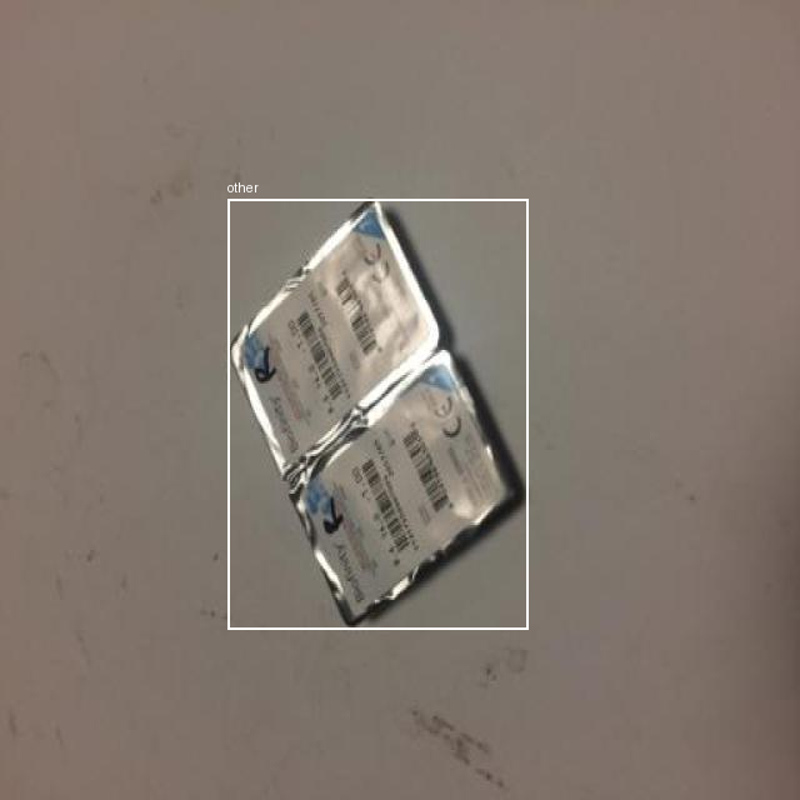

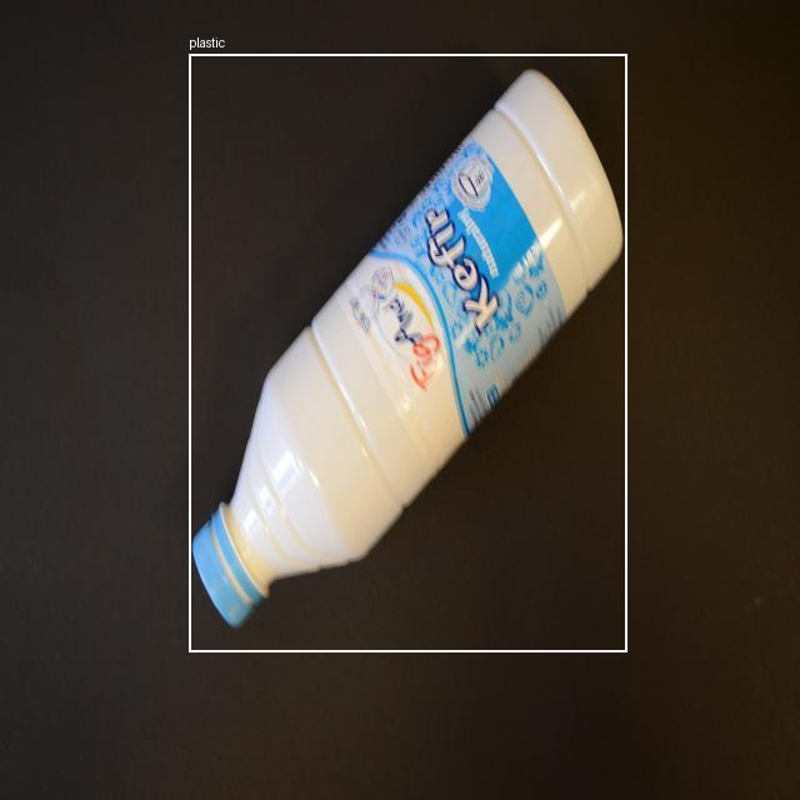

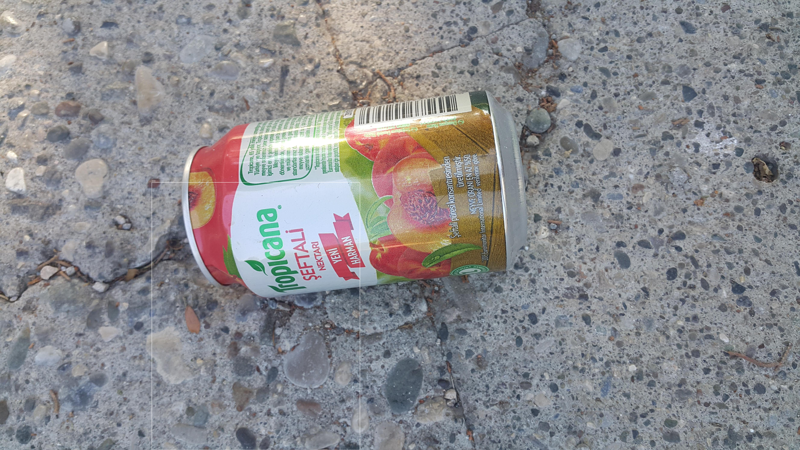


VAL


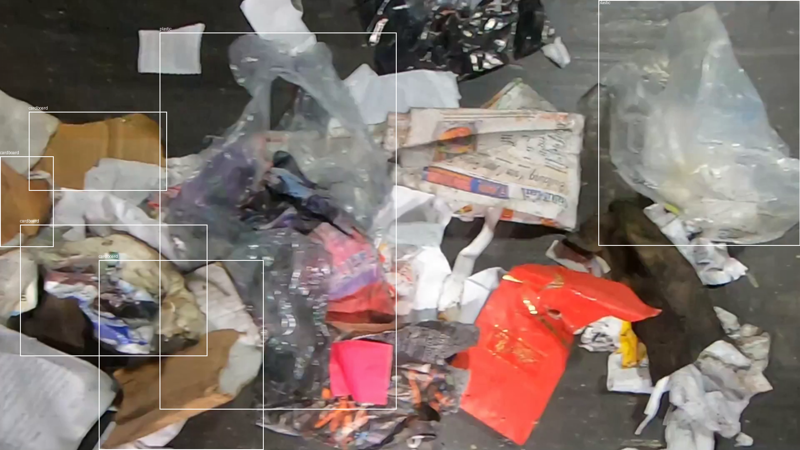

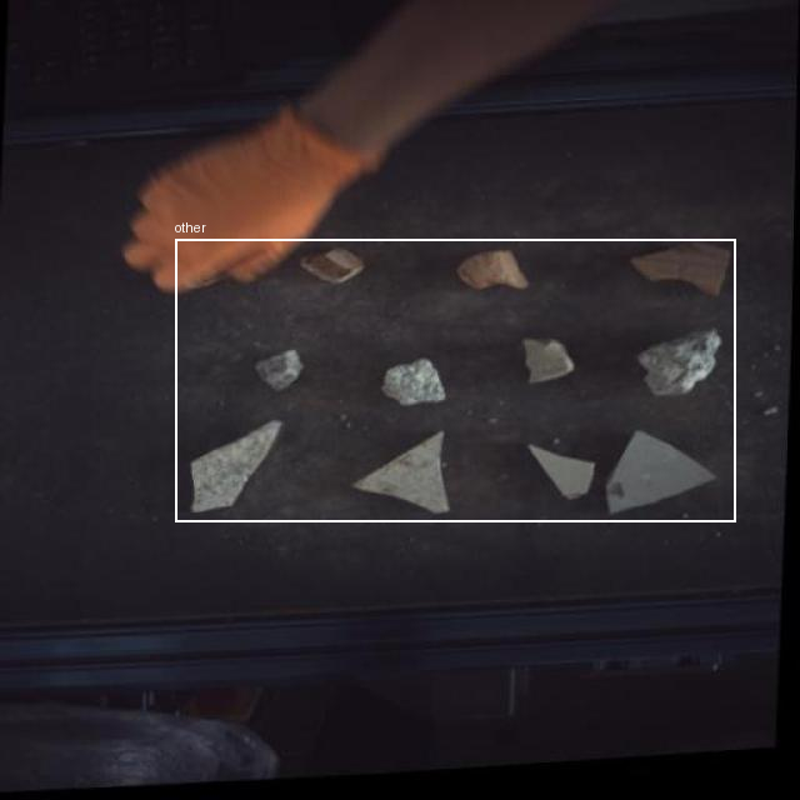

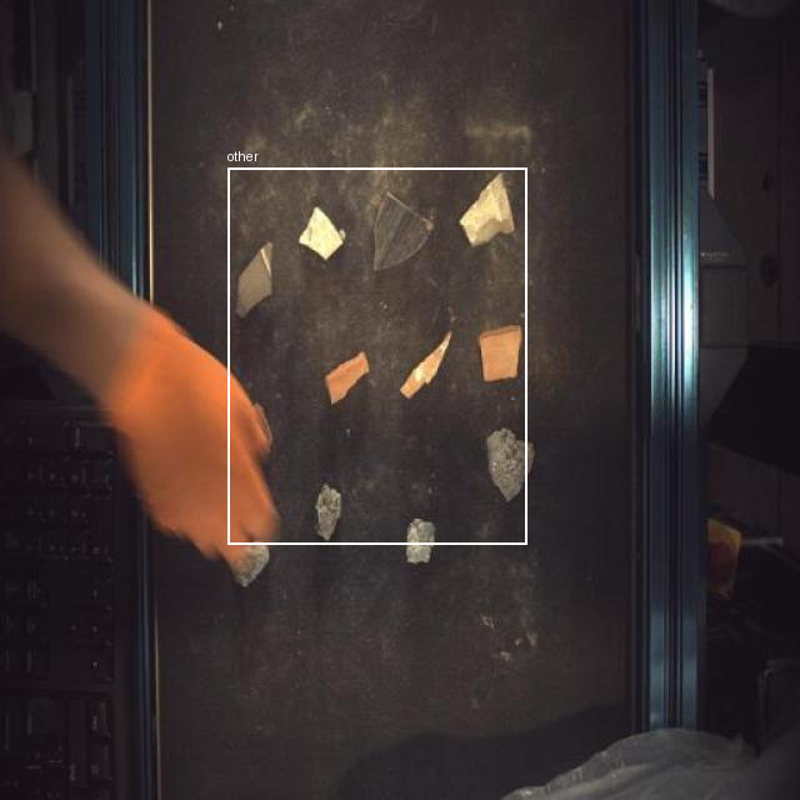


TEST


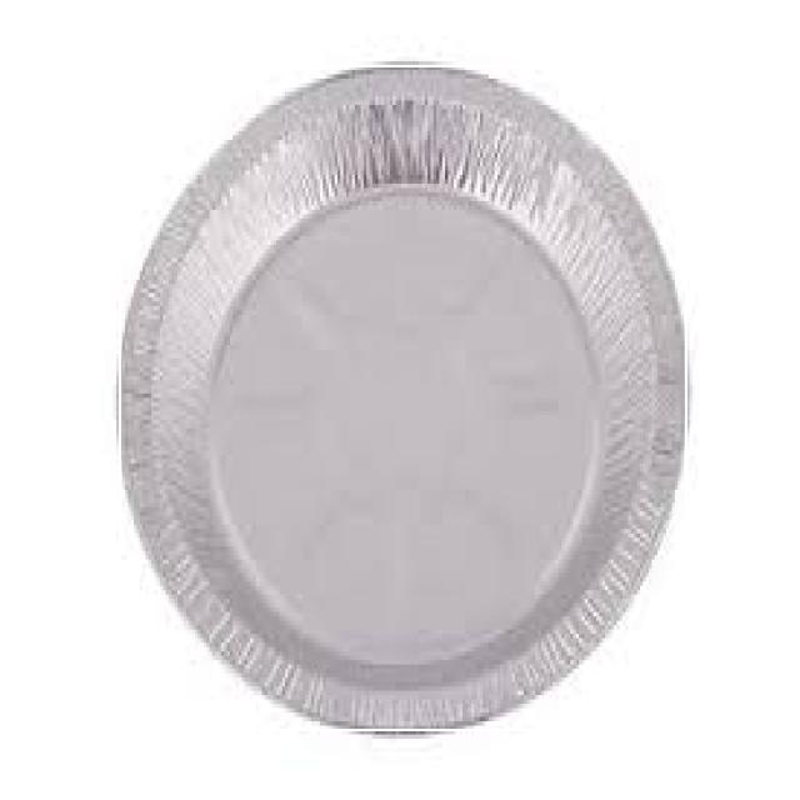

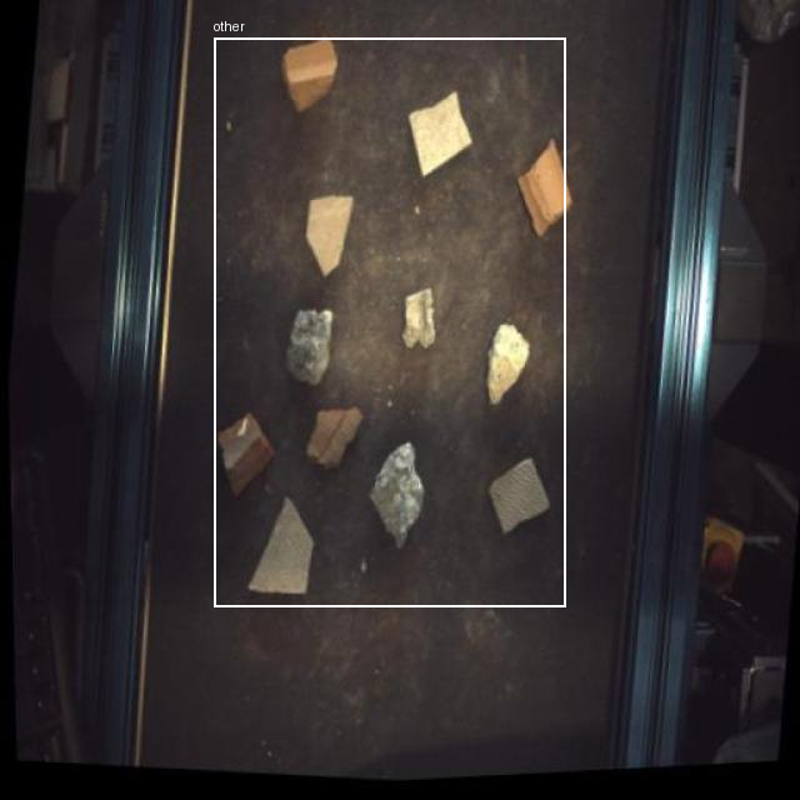

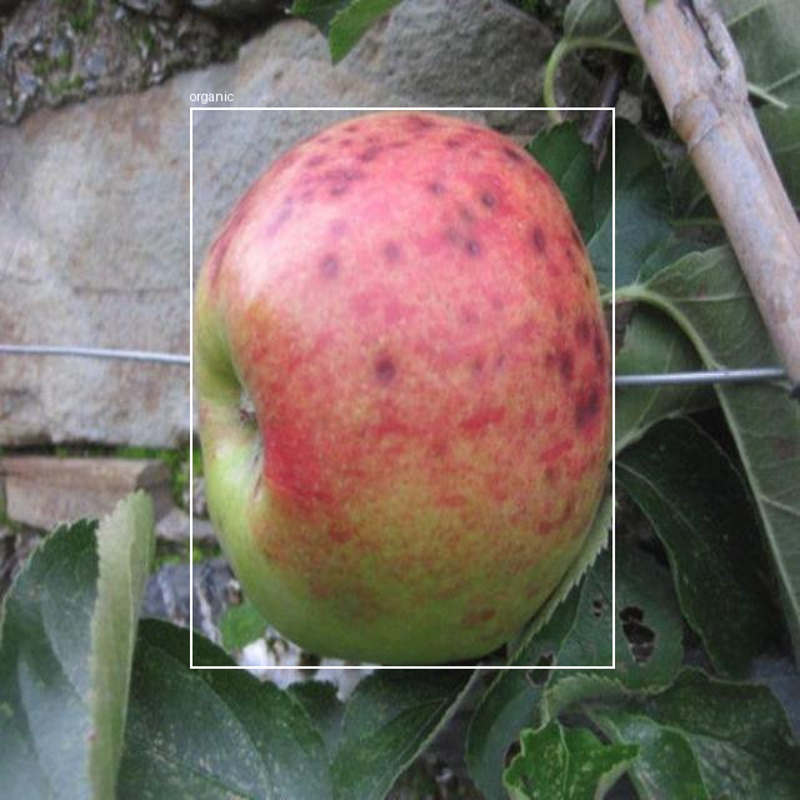

In [33]:
from pathlib import Path
import random
from PIL import Image, ImageDraw

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")

CLASS_NAMES = [
    "cardboard",
    "glass",
    "metal",
    "organic",
    "other",
    "paper",
    "plastic"
]

random.seed(42)

for split in ["train", "val", "test"]:
    image_dir = FINAL_DIR / split / "images"
    label_dir = FINAL_DIR / split / "labels"

    image_files = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ]

    samples = random.sample(image_files, min(3, len(image_files)))

    print(f"\n{split.upper()}")

    for image_path in samples:
        label_path = label_dir / f"{image_path.stem}.txt"

        image = Image.open(image_path).convert("RGB")
        draw = ImageDraw.Draw(image)

        width, height = image.size

        if label_path.exists():
            with open(label_path, "r", encoding="utf-8") as f:
                for line in f:
                    parts = line.strip().split()

                    if len(parts) != 5:
                        continue

                    class_id, x_center, y_center, box_width, box_height = map(
                        float, parts
                    )

                    class_id = int(class_id)

                    x1 = int((x_center - box_width / 2) * width)
                    y1 = int((y_center - box_height / 2) * height)
                    x2 = int((x_center + box_width / 2) * width)
                    y2 = int((y_center + box_height / 2) * height)

                    draw.rectangle([x1, y1, x2, y2], width=2)

                    draw.text(
                        (x1, max(0, y1 - 15)),
                        CLASS_NAMES[class_id]
                    )

        display(image.resize((800, int(800 * height / width))))

In [34]:
from pathlib import Path

MJU_DIR = Path(r"E:\ReNexa\data\raw\mju_waste")

print("=" * 60)
print("MJU-WASTE STRUCTURE")
print("=" * 60)

for item in MJU_DIR.iterdir():
    if item.is_dir():
        files = list(item.iterdir())
        print(f"\n{item.name}/")
        print("Files:", len(files))

        for file in files[:5]:
            print("  ", file.name)

    else:
        print("\n", item.name)

MJU-WASTE STRUCTURE

DepthImages/
Files: 2475
   2019-09-19_16_19_32-29_depth.png
   2019-09-19_16_19_44-93_depth.png
   2019-09-19_16_19_49-57_depth.png
   2019-09-19_16_19_55-63_depth.png
   2019-09-19_16_20_00-38_depth.png

ImageSets/
Files: 1
   Segmentation

JPEGImages/
Files: 2475
   2019-09-19_16_19_32-29_color.png
   2019-09-19_16_19_44-93_color.png
   2019-09-19_16_19_49-57_color.png
   2019-09-19_16_19_55-63_color.png
   2019-09-19_16_20_00-38_color.png

 readme.txt

SegmentationClass/
Files: 2475
   2019-09-19_16_19_32-29_color.png
   2019-09-19_16_19_44-93_color.png
   2019-09-19_16_19_49-57_color.png
   2019-09-19_16_19_55-63_color.png
   2019-09-19_16_20_00-38_color.png


In [35]:
README_FILE = MJU_DIR / "readme.txt"

print("=" * 60)
print("MJU-WASTE README")
print("=" * 60)

if README_FILE.exists():
    print(README_FILE.read_text(encoding="utf-8", errors="ignore"))
else:
    print("readme.txt not found")

MJU-WASTE README
# MJU-Waste v1.0

The official [MJU-Waste dataset](https://github.com/realwecan/mju-waste) repository.

### Paper

Please cite the following paper if you decide to use this dataset:

@article{wang2020multi,
  title={A Multi-Level Approach to Waste Object Segmentation},
  author={Wang, Tao and Cai, Yuanzheng and Liang, Lingyu and Ye, Dongyi},
  journal={Sensors},
  year={2020}
}

### Data

The dataset is provided in PASCAL VOC [1] format.
Object instance annotations in COCO [2] format are also available.

### References

[1] Everingham, M., Van Gool, L., Williams, C. K., Winn, J., & Zisserman, A. (2010). The pascal visual object classes (voc) challenge. International journal of computer vision, 88(2), 303-338.

[2] Lin, T. Y., Maire, M., Belongie, S., Hays, J., Perona, P., Ramanan, D., ... & Zitnick, C. L. (2014, September). Microsoft coco: Common objects in context. In European conference on computer vision (pp. 740-755). Springer, Cham.



In [36]:
from pathlib import Path

MJU_DIR = Path(r"E:\ReNexa\data\raw\mju_waste")

print("=" * 60)
print("MJU-WASTE ANNOTATION INSPECTION")
print("=" * 60)

# ImageSets
image_sets = MJU_DIR / "ImageSets"

print("\nImageSets:")
for item in image_sets.rglob("*"):
    if item.is_file():
        print(" ", item.relative_to(MJU_DIR))

# SegmentationClass
seg_dir = MJU_DIR / "SegmentationClass"

print("\nSegmentationClass:")
if seg_dir.exists():
    mask_files = list(seg_dir.iterdir())
    print("Mask files:", len(mask_files))

    for file in mask_files[:10]:
        print(" ", file.name)
else:
    print("SegmentationClass folder not found")

# COCO / JSON files
print("\nJSON annotation files:")

json_files = list(MJU_DIR.rglob("*.json"))

if json_files:
    for file in json_files:
        print(" ", file.relative_to(MJU_DIR))
else:
    print("No JSON files found")

MJU-WASTE ANNOTATION INSPECTION

ImageSets:
  ImageSets\Segmentation\test.txt
  ImageSets\Segmentation\train.txt
  ImageSets\Segmentation\trainval.txt
  ImageSets\Segmentation\val.txt

SegmentationClass:
Mask files: 2475
  2019-09-19_16_19_32-29_color.png
  2019-09-19_16_19_44-93_color.png
  2019-09-19_16_19_49-57_color.png
  2019-09-19_16_19_55-63_color.png
  2019-09-19_16_20_00-38_color.png
  2019-09-19_16_20_06-93_color.png
  2019-09-19_16_20_11-29_color.png
  2019-09-19_16_20_17-93_color.png
  2019-09-19_16_20_22-04_color.png
  2019-09-19_16_20_30-29_color.png

JSON annotation files:
No JSON files found


In [37]:
from PIL import Image
import numpy as np

MJU_DIR = Path(r"E:\ReNexa\data\raw\mju_waste")
MASK_DIR = MJU_DIR / "SegmentationClass"

mask_files = list(MASK_DIR.glob("*.png"))

print("=" * 60)
print("MJU SEGMENTATION MASK VALUES")
print("=" * 60)

all_values = set()

for mask_file in mask_files[:20]:
    mask = np.array(Image.open(mask_file))

    unique_values = np.unique(mask)
    all_values.update(unique_values.tolist())

    print(f"\n{mask_file.name}")
    print("Shape:", mask.shape)
    print("Unique values:", unique_values)

print("\n" + "=" * 60)
print("VALUES FOUND IN FIRST 20 MASKS")
print("=" * 60)
print(sorted(all_values))

MJU SEGMENTATION MASK VALUES

2019-09-19_16_19_32-29_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_19_44-93_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_19_49-57_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_19_55-63_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_00-38_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_06-93_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_11-29_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_17-93_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_22-04_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_30-29_color.png
Shape: (480, 640)
Unique values: [0]

2019-09-19_16_20_37-17_color.png
Shape: (480, 640)
Unique values: [0]

2019-09-19_16_20_44-83_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_49-60_color.png
Shape: (480, 640)
Unique values: [0 1]

2019-09-19_16_20_55-21_co

In [38]:
from pathlib import Path
from collections import Counter

FINAL_DIR = Path(r"E:\ReNexa\data\processed\renexa_detection_final")

CLASS_NAMES = [
    "cardboard",
    "glass",
    "metal",
    "organic",
    "other",
    "paper",
    "plastic"
]

print("=" * 60)
print("FINAL CLASS DISTRIBUTION BY SPLIT")
print("=" * 60)

for split in ["train", "val", "test"]:

    counts = Counter()

    label_dir = FINAL_DIR / split / "labels"

    for label_file in label_dir.glob("*.txt"):

        with open(label_file, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    class_id = int(parts[0])
                    counts[class_id] += 1

    print(f"\n{split.upper()}")

    for class_id, class_name in enumerate(CLASS_NAMES):
        print(f"{class_id}: {class_name:10} -> {counts[class_id]}")


FINAL CLASS DISTRIBUTION BY SPLIT

TRAIN
0: cardboard  -> 12107
1: glass      -> 2919
2: metal      -> 3639
3: organic    -> 4994
4: other      -> 4712
5: paper      -> 2181
6: plastic    -> 12987

VAL
0: cardboard  -> 2376
1: glass      -> 214
2: metal      -> 282
3: organic    -> 621
4: other      -> 648
5: paper      -> 246
6: plastic    -> 2177

TEST
0: cardboard  -> 3468
1: glass      -> 216
2: metal      -> 270
3: organic    -> 489
4: other      -> 506
5: paper      -> 303
6: plastic    -> 2336
